# 04 · Model Training, Validation & Evaluation

**Goal:** compare baselines and machine-learning models fairly, choose the final model using **validation data only**, and evaluate it **once** on the untouched test set.

**What happened, in order (all implemented in `src/train.py`)**

1. Split chronologically: *pool* (before 2011-11-09) and *test* (last 30 days).
2. Score 4 baselines and 15 model configurations (Linear Regression, Random Forest, XGBoost) on **4 expanding-window folds** of the pool.
3. Select the final model by the lowest **mean validation MAE** under the 30-day recursive protocol.
4. Evaluate that one model on the test set (a single evaluation).
5. Refit the chosen configuration on all data, save it, and forecast 30 days ahead.

This notebook does **not** retrain the models: training is deterministic and already done (`python -m src.train`, about one minute). It re-computes the cheap parts live (baselines and one model fold) to prove the saved results are reproducible, then analyses the saved results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the project root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from src import config, plotting
import json
from src import data_preprocessing as dp, evaluate as ev, feature_engineering as fe, forecast as fc, train as tr
plotting.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
GBP = FuncFormatter(plotting.gbp)
print("project folder:", ROOT.name)

project folder: retail-sales-forecasting


## 1 · Chronological split and validation folds

In [2]:
series = dp.load_revenue_series()
pool, test = ev.chronological_split(series)
folds = ev.expanding_window_folds(pool.index)
tr.verify_frozen_split(series, pool, test, folds)         # raises if the data and the frozen config disagree

table = pd.DataFrame([{"fold": f.fold, "train": f"{series.index[0].date()} -> {f.train_end.date()}",
                       "validation": f"{f.val_start.date()} -> {f.val_end.date()}"} for f in folds])
table.loc[len(table)] = ["TEST", f"{pool.index[0].date()} -> {pool.index[-1].date()} (pool)", f"{test.index[0].date()} -> {test.index[-1].date()}"]
table

,fold,train,validation
0,1,2009-12-01 -> 2011-07-11,2011-07-12 -> 2011-08-10
1,2,2009-12-01 -> 2011-08-10,2011-08-11 -> 2011-09-09
2,3,2009-12-01 -> 2011-09-09,2011-09-10 -> 2011-10-09
3,4,2009-12-01 -> 2011-10-09,2011-10-10 -> 2011-11-08
4,TEST,2009-12-01 -> 2011-11-08 (pool),2011-11-09 -> 2011-12-08


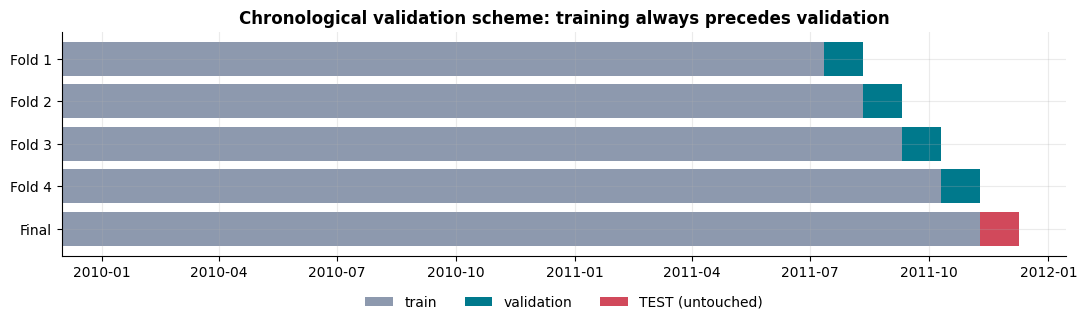

In [3]:
import matplotlib.dates as mdates
start = series.index[0]
fig, ax = plt.subplots(figsize=(11, 3.4))
labels = []
for f in folds:
    labels.append(f"Fold {f.fold}")
    ax.barh(len(labels) - 1, (f.train_end - start).days + 1, left=mdates.date2num(start), color=plotting.COLORS["muted"], label="train" if f.fold == 1 else None)
    ax.barh(len(labels) - 1, (f.val_end - f.val_start).days + 1, left=mdates.date2num(f.val_start), color=plotting.COLORS["accent"], label="validation" if f.fold == 1 else None)
labels.append("Final")
ax.barh(len(labels) - 1, len(pool), left=mdates.date2num(start), color=plotting.COLORS["muted"])
ax.barh(len(labels) - 1, len(test), left=mdates.date2num(test.index[0]), color=plotting.COLORS["forecast"], label="TEST (untouched)")
ax.set_yticks(range(len(labels)), labels=labels)
ax.invert_yaxis()
ax.xaxis_date()
ax.set_title("Chronological validation scheme: training always precedes validation")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.tight_layout()
plotting.save_figure(fig, "fig14_validation_scheme.png")
plt.show()

**Why not ordinary random K-fold?** Random folds would put 2011 days in the training set while scoring on 2010 days, so the model could learn from the future of the days it is judged on. Revenue also has strong autocorrelation (lag 7 ~ 0.6), so neighbouring days leak information to each other. Real forecasting only ever predicts forward, so the validation must too. Expanding windows do exactly that and also show how stable a model is across different periods.

## 2 · Baselines (the bar every model must clear)

| Baseline | Idea |
|---|---|
| Naive | tomorrow = the last observed day |
| Seasonal naive | same weekday as last week |
| Moving average (7 days) | average of the last 7 days |
| Seasonal average (4 weeks) | average of the same weekday over the last 4 weeks |

A model that cannot beat these is not worth deploying. All baselines get the same "known closure = 0" rule as the models, so the comparison is fair.

Two evaluation protocols are reported:

* **30-day recursive** (primary): forecast 30 days ahead from the end of training, feeding forecasts back as lags. This is exactly how the deployed 30-day forecast works.
* **1-day-ahead** (secondary): each day is forecast using actuals up to the previous day, as in a daily refresh.

In [4]:
saved_folds = pd.read_csv(config.VALIDATION_FOLD_METRICS_FILE)
live, _ = tr.run_validation(pool, folds, specs=[], verbose=False)       # baselines only (fast)
check = live.merge(saved_folds, on=["model", "fold", "protocol"], suffixes=("_live", "_saved"))
max_diff = (check["mae_live"] - check["mae_saved"]).abs().max()
print(f"Recomputed {len(check)} baseline fold scores live; largest MAE difference vs saved results: {max_diff:.4f}")
assert max_diff < 0.01

Recomputed 32 baseline fold scores live; largest MAE difference vs saved results: 0.0000


In [5]:
# one model fold recomputed live (Linear Regression, fold 4) as a reproducibility spot-check
spec = tr.ModelSpec("Linear Regression", "linear")
live_lr, _ = tr.run_validation(pool, [folds[-1]], [spec], verbose=False)
live_value = live_lr[(live_lr["model"] == "Linear Regression") & (live_lr["protocol"] == tr.PROTOCOL_RECURSIVE)]["mae"].iloc[0]
saved_value = saved_folds[(saved_folds["model"] == "Linear Regression") & (saved_folds["fold"] == 4)
                          & (saved_folds["protocol"] == tr.PROTOCOL_RECURSIVE)]["mae"].iloc[0]
print(f"Linear Regression, fold 4, 30-day MAE: live {live_value:,.2f} vs saved {saved_value:,.2f}")
assert abs(live_value - saved_value) < 0.01

Linear Regression, fold 4, 30-day MAE: live 9,412.13 vs saved 9,412.13


## 3 · Validation results (pool only)

In [6]:
comparison = pd.read_csv(config.MODEL_COMPARISON_FILE)
val = comparison[comparison["split"].str.startswith("validation")]
cols = ["model", "mae", "rmse", "smape_trading_days", "wape", "r2"]
for protocol in ("30-day recursive", "1-day-ahead"):
    print(f"=== {protocol} (mean of 4 validation folds) ===")
    print(val[val["protocol"] == protocol].sort_values("mae")[cols].round(2).to_string(index=False))
    print()

=== 30-day recursive (mean of 4 validation folds) ===
                                        model       mae      rmse  smape_trading_days  wape    r2
            XGBoost (n=400, depth=5, lr=0.03)  8,490.07 12,865.91               28.71 27.76  0.55
       Random Forest (depth=None, min_leaf=1)  9,146.51 13,600.91               30.41 29.58  0.50
                            Linear Regression  9,364.67 13,129.64               29.33 30.23  0.53
Seasonal average (same weekday, last 4 weeks) 10,594.12 15,080.33               36.01 33.84  0.41
      Seasonal naive (same weekday last week) 11,601.47 16,737.83               38.72 36.98  0.26
                 Moving average (last 7 days) 15,241.26 20,009.87               38.82 49.07 -0.07
                    Naive (last observed day) 18,254.56 22,536.49               55.14 56.91 -0.42

=== 1-day-ahead (mean of 4 validation folds) ===
                                        model       mae      rmse  smape_trading_days  wape    r2
            XG

### What the metrics mean for retail sales forecasting

| Metric | Plain-language meaning | Use here |
|---|---|---|
| **MAE** | the average size of a daily miss, in pounds | **Primary metric.** Easy to explain, in business units, robust to the occasional huge day and well-defined on closed days |
| **RMSE** | like MAE but squares errors, so a few large misses weigh more | Secondary: tells us whether a model is prone to big misses on peak days |
| **WAPE** | total absolute miss as % of total revenue | The percentage view that stays valid when some days have zero revenue |
| **sMAPE (trading days)** | symmetric % error on days that traded | Percent view; closed days are excluded because a percentage of zero is meaningless (plain MAPE would divide by zero) |
| **R-squared** | share of day-to-day variation explained | Supplementary only; it is not used to select models |

Why MAE for selection? Daily revenue has zero days and a skewed distribution. MAE answers the question a planner actually asks ("how many pounds are we typically off per day?"), while percentage errors explode when the denominator is small and R-squared mostly measures whether we got the weekday pattern right.

In [7]:
hp = pd.read_csv(config.HYPERPARAMETER_SEARCH_FILE)
rec = hp[(hp["protocol"] == "30-day recursive") & (hp["kind"] == "ml")].sort_values("mae")
print("Top 8 of 15 configurations by mean validation MAE (30-day recursive):")
print(rec[["model", "mae", "rmse", "wape"]].head(8).round(2).to_string(index=False))
print("\nBest configuration per family:")
print(rec.groupby("family").head(1)[["family", "model", "mae", "rmse", "wape"]].round(2).to_string(index=False))
edge = rec[rec["family"] == "random_forest"].iloc[0]["model"]
print("\nBest Random Forest:", edge, "(note: depth=None, min_leaf=1 is at the edge of the grid)")

Top 8 of 15 configurations by mean validation MAE (30-day recursive):
                                 model      mae      rmse  wape
     XGBoost (n=400, depth=5, lr=0.03) 8,490.07 12,865.91 27.76
      XGBoost (n=200, depth=5, lr=0.1) 8,702.10 12,739.10 28.47
      XGBoost (n=400, depth=5, lr=0.1) 8,760.24 12,916.18 28.71
      XGBoost (n=400, depth=3, lr=0.1) 9,110.31 13,315.97 29.95
Random Forest (depth=None, min_leaf=1) 9,146.51 13,600.91 29.58
Random Forest (depth=None, min_leaf=3) 9,268.07 13,923.15 29.93
     XGBoost (n=200, depth=5, lr=0.03) 9,270.80 13,482.92 29.95
   Random Forest (depth=8, min_leaf=1) 9,361.25 13,911.83 30.23

Best configuration per family:
       family                                  model      mae      rmse  wape
      xgboost      XGBoost (n=400, depth=5, lr=0.03) 8,490.07 12,865.91 27.76
random_forest Random Forest (depth=None, min_leaf=1) 9,146.51 13,600.91 29.58
       linear                      Linear Regression 9,364.67 13,129.64 30.23

Best Rand

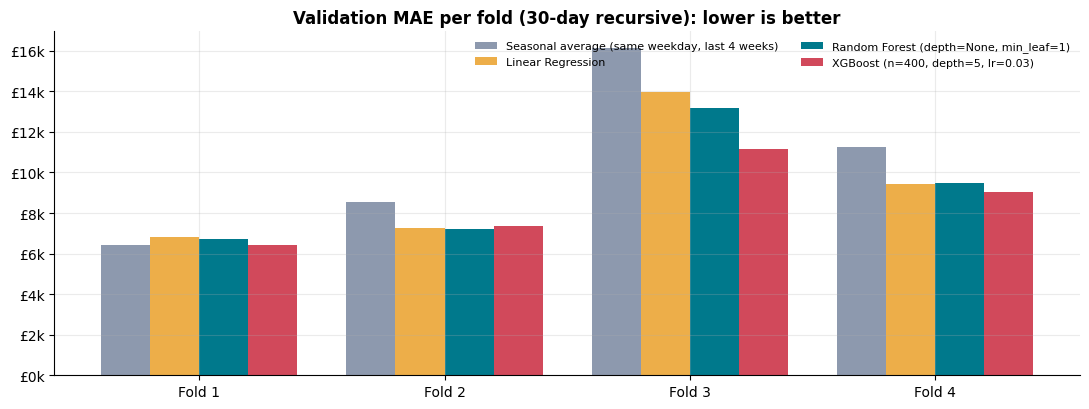

model  Seasonal average (same weekday, last 4 weeks)  Linear Regression  Random Forest (depth=None, min_leaf=1)  XGBoost (n=400, depth=5, lr=0.03)
fold                                                                                                                                              
1                                           6,433.00           6,813.00                                6,713.00                           6,438.00
2                                           8,538.00           7,245.00                                7,210.00                           7,346.00
3                                          16,151.00          13,988.00                               13,199.00                          11,137.00
4                                          11,255.00           9,412.00                                9,465.00                           9,039.00


In [8]:
folds_df = pd.read_csv(config.VALIDATION_FOLD_METRICS_FILE)
rec_folds = folds_df[folds_df["protocol"] == "30-day recursive"]
meta = json.loads(config.MODEL_METADATA_FILE.read_text())
final_name = meta["model_name"]
best_rf = rec[rec["family"] == "random_forest"].iloc[0]["model"]
best_baseline = val[(val["protocol"] == "30-day recursive") & (val["kind"] == "baseline")].sort_values("mae").iloc[0]["model"]
shown = [best_baseline, "Linear Regression", best_rf, final_name]

pivot = rec_folds[rec_folds["model"].isin(shown)].pivot(index="fold", columns="model", values="mae")[shown]
fig, ax = plt.subplots(figsize=(11, 4.2))
width = 0.2
palette = [plotting.COLORS["muted"], plotting.COLORS["highlight"], plotting.COLORS["accent"], plotting.COLORS["forecast"]]
for i, name in enumerate(shown):
    ax.bar(np.arange(4) + (i - 1.5) * width, pivot[name].values, width, label=name, color=palette[i])
ax.set_xticks(range(4), labels=[f"Fold {k}" for k in pivot.index])
ax.yaxis.set_major_formatter(GBP)
ax.set_title("Validation MAE per fold (30-day recursive): lower is better")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plotting.save_figure(fig, "fig15_validation_mae_by_fold.png")
plt.show()
print(pivot.round(0).to_string())

## 4 · Model selection (validation only) and trade-offs

In [9]:
rows = val[val["protocol"] == "30-day recursive"].set_index("model")
winner = rows[rows["kind"] == "ml"]["mae"].idxmin()
assert winner == final_name, "the saved model must be the validation winner"
print(f"Selected on validation: {winner}  (selection rule: {meta['selection_rule']})\n")

base = rows.loc[best_baseline]
for name in [winner, best_rf, "Linear Regression"]:
    r = rows.loc[name]
    print(f"{name}: MAE {r['mae']:,.0f} ({(1 - r['mae'] / base['mae']) * 100:.1f}% below best baseline), "
          f"RMSE {r['rmse']:,.0f}, WAPE {r['wape']:.1f}%")
print(f"Best baseline ({best_baseline}): MAE {base['mae']:,.0f}, RMSE {base['rmse']:,.0f}, WAPE {base['wape']:.1f}%")

fold_best = pivot.idxmin(axis=1)
print("\nLowest MAE in each fold:", dict(fold_best))
beaten = (pivot[winner] < pivot[best_baseline])
print(f"Selected model beats the best baseline in {int(beaten.sum())} of 4 folds "
      f"(fold MAEs: model {pivot[winner].round(0).tolist()} vs baseline {pivot[best_baseline].round(0).tolist()})")
spread = rec_folds[rec_folds["model"].isin([winner, "Linear Regression", best_rf])].groupby("model")["mae"].agg(["mean", "std"])
print("\nFold-to-fold variation of MAE (mean, std):"); print(spread.round(0).to_string())

Selected on validation: XGBoost (n=400, depth=5, lr=0.03)  (selection rule: lowest mean MAE over validation folds, 30-day recursive protocol; test set not used)

XGBoost (n=400, depth=5, lr=0.03): MAE 8,490 (19.9% below best baseline), RMSE 12,866, WAPE 27.8%
Random Forest (depth=None, min_leaf=1): MAE 9,147 (13.7% below best baseline), RMSE 13,601, WAPE 29.6%
Linear Regression: MAE 9,365 (11.6% below best baseline), RMSE 13,130, WAPE 30.2%
Best baseline (Seasonal average (same weekday, last 4 weeks)): MAE 10,594, RMSE 15,080, WAPE 33.8%

Lowest MAE in each fold: {1: 'Seasonal average (same weekday, last 4 weeks)', 2: 'Random Forest (depth=None, min_leaf=1)', 3: 'XGBoost (n=400, depth=5, lr=0.03)', 4: 'XGBoost (n=400, depth=5, lr=0.03)'}
Selected model beats the best baseline in 3 of 4 folds (fold MAEs: model [6438.0, 7346.0, 11137.0, 9039.0] vs baseline [6433.0, 8538.0, 16151.0, 11255.0])

Fold-to-fold variation of MAE (mean, std):
                                           mean      

**Reading the trade-offs honestly**

* The selected model has the lowest mean validation MAE, but **no model wins every fold** (see the "lowest MAE in each fold" line above), and its average lead is helped a lot by one fold (fold 3). In fold 1 the best baseline is effectively tied with it.
* **The ranking depends on the metric.** On RMSE, Linear Regression ranks ahead of Random Forest, and a different XGBoost configuration (n=200, lr=0.1) has a slightly lower RMSE than the selected one. Under the 1-day-ahead protocol Linear Regression has the lowest RMSE of all models. We selected on MAE because it is the primary business metric and was fixed *before* looking at results.
* **Linear Regression** is simple, fast, easy to explain in an interview and nearly as accurate; the tree models have a bit more flexibility.
* The validation scores come from only **four 30-day windows** of one business, so they are noisy. Treat small gaps between models as ties, and treat the gap to the *baselines* (large and consistent) as the real finding.
* Because the winner was picked on these same folds, its validation score is slightly optimistic; the untouched test set below is the unbiased check.

## 5 · Final evaluation on the untouched test set (performed once)

In [10]:
test_rows = comparison[comparison["split"].str.startswith("test")]
for protocol in ("30-day recursive", "1-day-ahead"):
    print(f"=== TEST, {protocol} ===")
    print(test_rows[test_rows["protocol"] == protocol].sort_values("mae")[cols].round(2).to_string(index=False))
    print()
tm = meta["test_metrics_pool_trained_model"]["30-day recursive"]
bt = test_rows[(test_rows["protocol"] == "30-day recursive") & (test_rows["kind"] == "baseline")].sort_values("mae").iloc[0]
print(f"Selected model, 30-day recursive test MAE {tm['mae']:,.0f} vs best baseline on test ({bt['model']}) {bt['mae']:,.0f}: "
      f"{(1 - tm['mae'] / bt['mae']) * 100:.1f}% lower")
print(f"Test R-squared {tm['r2']:.2f}, WAPE {tm['wape']:.1f}%, sMAPE on trading days {tm['smape_trading_days']:.1f}%")
print("\nNote:", meta["test_note"])

=== TEST, 30-day recursive ===
                                        model       mae      rmse  smape_trading_days  wape    r2
            XGBoost (n=400, depth=5, lr=0.03)  8,674.13 13,275.75               16.86 17.49  0.74
      Seasonal naive (same weekday last week) 12,763.05 16,162.75               26.80 25.74  0.61
Seasonal average (same weekday, last 4 weeks) 13,342.68 19,085.02               28.49 26.91  0.46
                    Naive (last observed day) 18,859.34 26,442.51               24.44 38.04 -0.04
                 Moving average (last 7 days) 19,329.86 25,938.56               26.84 38.99 -0.00

=== TEST, 1-day-ahead ===
                                        model       mae      rmse  smape_trading_days  wape    r2
            XGBoost (n=400, depth=5, lr=0.03)  8,198.25 13,183.50               15.62 16.53  0.74
      Seasonal naive (same weekday last week) 10,856.35 16,583.71               20.90 21.90  0.59
Seasonal average (same weekday, last 4 weeks) 11,599.78 16,2

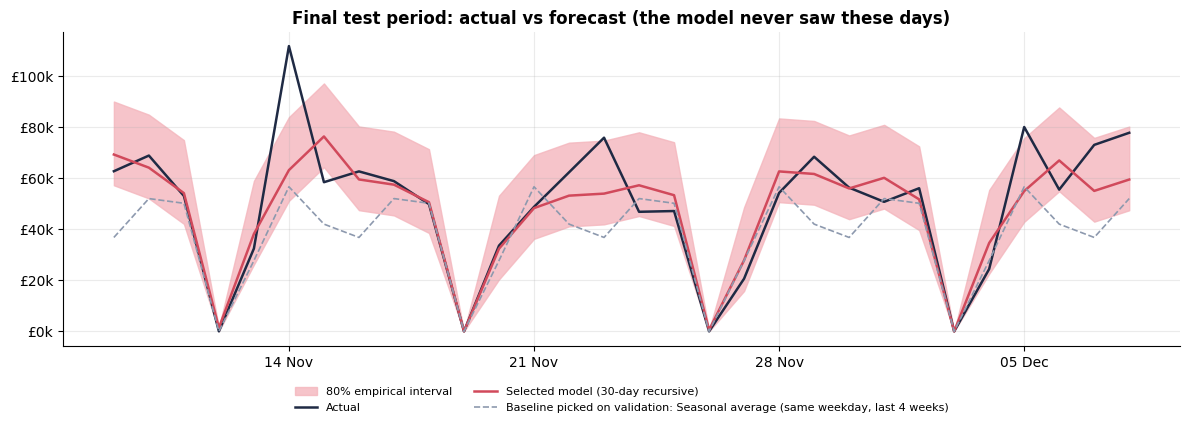

Actual revenue inside the 80% interval on 25 of 30 test days (83.3%; nominal 80%)


In [11]:
pred = pd.read_csv(config.TEST_PREDICTIONS_FILE, parse_dates=["date"]).set_index("date")
base_col = {"Seasonal average (same weekday, last 4 weeks)": "baseline_seasonal_average_4w"}.get(best_baseline)

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.fill_between(pred.index, pred["lower"], pred["upper"], color=plotting.COLORS["interval"], alpha=0.8, label="80% empirical interval")
ax.plot(pred.index, pred["actual"], color=plotting.COLORS["actual"], lw=1.8, label="Actual")
ax.plot(pred.index, pred["forecast"], color=plotting.COLORS["forecast"], lw=1.8, label="Selected model (30-day recursive)")
if base_col:
    ax.plot(pred.index, pred[base_col], color=plotting.COLORS["muted"], lw=1.2, ls="--", label=f"Baseline picked on validation: {best_baseline}")
ax.yaxis.set_major_formatter(GBP)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))      # a tick every Monday
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Final test period: actual vs forecast (the model never saw these days)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
plotting.save_figure(fig, "fig16_test_forecast_vs_actual.png")
plt.show()

inside = ((pred["actual"] >= pred["lower"]) & (pred["actual"] <= pred["upper"]))
print(f"Actual revenue inside the 80% interval on {int(inside.sum())} of {len(pred)} test days ({inside.mean() * 100:.1f}%; nominal 80%)")

**Interpretation.** The shaded band is an *empirical* interval: it is built from the model's own out-of-sample errors on the validation folds (separately for open and closed days), not from a statistical formula. Its test coverage (printed above) is a useful check, but with only 30 test days it is itself imprecise. The interval is an approximation, not a guarantee.

**Honest caveats.** WAPE, sMAPE and R-squared look better on the test period than on validation partly because November revenue is much higher (percentage errors are measured against a bigger denominator) while absolute MAE is similar to validation. That is a property of the window, not evidence of a better model. The test window also contains one very large day (2011-11-14, about GBP 112k) that the model under-predicts (see notebook 05).

## 6 · What does the final model use? (feature importance)

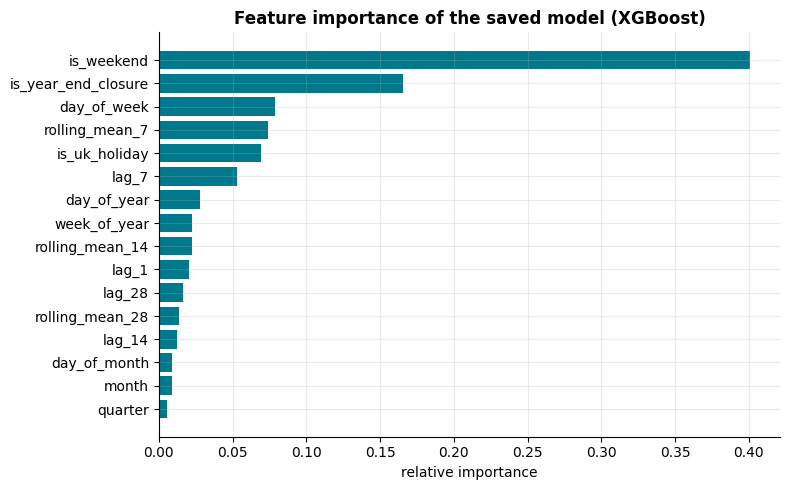

is_weekend            0.40
is_year_end_closure   0.17
day_of_week           0.08
rolling_mean_7        0.07
is_uk_holiday         0.07
lag_7                 0.05
day_of_year           0.03
week_of_year          0.02


In [12]:
model, _ = fc.load_artifacts()
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=fe.FEATURE_COLUMNS).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(imp.index, imp.values, color=plotting.COLORS["accent"])
    ax.set_title(f"Feature importance of the saved model ({meta['model_family']})")
    ax.set_xlabel("relative importance")
    fig.tight_layout()
    plotting.save_figure(fig, "fig17_feature_importance.png")
    plt.show()
    print(imp.sort_values(ascending=False).round(3).head(8).to_string())
else:
    print("The saved model has no feature_importances_ attribute.")

**How to read it.** Most of the importance sits on the calendar flags that separate *closed* from *open* days (`is_weekend`, `is_year_end_closure`, `is_uk_holiday`, `day_of_week`). That is expected: telling a closed day (revenue 0) from an open day (about GBP 30k) is by far the biggest source of variation. The recent-level and lag features matter for *how busy an open day is*, but individually carry smaller shares. Importance shows what the model relied on when splitting, not that a feature *causes* revenue, and correlated features (the several rolling means and lags) share importance, so individual values should be read loosely.